# Project 03: E-Commerce Sales Trend & Customer Segmentation Analysis
**Data Source Note:** This project uses a **simulated e-commerce dataset** generated via `numpy.random.default_rng(42)` (`n = 2,000` orders across `300` unique customer IDs over the 2025 calendar year). Order amounts follow a Gamma distribution (`shape=2.0, scale=600`) to realistically model right-skewed retail order values.

## 1. Business Questions
As an e-commerce analytics team reporting to management, this analysis answers three core operational questions:
1. **Seasonality & Revenue Trends:** Which months and quarters generate the highest revenue, and what is our month-over-month (MoM) growth trajectory?
2. **Category Performance:** Which product categories (`Electronics`, `Fashion`, `Home`, `Books`) drive the most total revenue, order volume, and average order value (AOV)?
3. **Customer Concentration (Pareto / 80-20 Rule):** Who are our highest-value customers, what exact share of revenue comes from the top 10% of buyers, and what concrete retention actions should we take next?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
rng = np.random.default_rng(42)
n = 2000
orders = pd.DataFrame({
    "order_date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
    "customer_id": rng.integers(1, 301, n),
    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"], 
        size=n, 
        p=[0.30, 0.35, 0.20, 0.15]
    ),
    "amount": rng.gamma(2.0, 600, n).round(2),
})
print("=== DATA QUALITY AUDIT ===")
print(f"Dataset Shape          : {orders.shape[0]} rows, {orders.shape[1]} columns")
print(f"Date Range             : {orders['order_date'].min().date()} to {orders['order_date'].max().date()}")
print(f"Unique Customers       : {orders['customer_id'].nunique()}")
print(f"Duplicate Rows         : {orders.duplicated().sum()}")
print("\n--- Data Types & Null Counts ---")
audit_df = pd.DataFrame({
    "Data Type": orders.dtypes,
    "Missing Values": orders.isnull().sum(),
    "Missing (%)": (orders.isnull().sum() / len(orders) * 100).round(2)
})
print(audit_df)
print("\n--- Summary Statistics ---")
display(orders.describe().round(2))
display(orders.head())

=== DATA QUALITY AUDIT ===
Dataset Shape          : 2000 rows, 4 columns
Date Range             : 2025-01-01 to 2025-12-31
Unique Customers       : 300
Duplicate Rows         : 0

--- Data Types & Null Counts ---
                  Data Type  Missing Values  Missing (%)
order_date   datetime64[us]               0          0.0
customer_id           int64               0          0.0
category                str               0          0.0
amount              float64               0          0.0

--- Summary Statistics ---


,order_date,customer_id,amount
count,2000,2000.00,2000.00
mean,2025-07-01 22:45:07.200000,151.20,1202.12
min,2025-01-01 00:00:00,1.00,8.81
25%,2025-03-31 18:00:00,74.00,597.52
50%,2025-07-02 00:00:00,149.00,1005.87
75%,2025-10-03 00:00:00,226.00,1613.86
max,2025-12-31 00:00:00,300.00,6276.09
std,NaN,86.21,826.96


,order_date,customer_id,category,amount
0,2025-02-02,264,Home,391.13
1,2025-10-10,19,Fashion,2456.21
2,2025-08-27,120,Books,674.90
3,2025-06-10,138,Home,75.38
4,2025-06-08,240,Electronics,774.42


In [2]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
orders["month"] = orders["order_date"].dt.to_period("M")
orders["quarter"] = orders["order_date"].dt.to_period("Q")
orders["weekday"] = orders["order_date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
orders["weekday"] = pd.Categorical(orders["weekday"], categories=weekday_order, ordered=True)
print("Engineered Date Features Preview:")
display(orders[["order_date", "month", "quarter", "weekday", "category", "amount"]].head(8))

Engineered Date Features Preview:


,order_date,month,quarter,weekday,category,amount
0,2025-02-02,2025-02,2025Q1,Sunday,Home,391.13
1,2025-10-10,2025-10,2025Q4,Friday,Fashion,2456.21
2,2025-08-27,2025-08,2025Q3,Wednesday,Books,674.90
3,2025-06-10,2025-06,2025Q2,Tuesday,Home,75.38
4,2025-06-08,2025-06,2025Q2,Sunday,Electronics,774.42
5,2025-11-10,2025-11,2025Q4,Monday,Books,1181.46
6,2025-02-01,2025-02,2025Q1,Saturday,Fashion,1271.72
7,2025-09-12,2025-09,2025Q3,Friday,Electronics,366.39


Total 2025 Revenue : $2,404,233.29
Best Month         : 2025-02 ($232,027.20 | 182 orders)
Worst Month        : 2025-08 ($179,783.75 | 165 orders)



,month_str,total_revenue,order_count,avg_order_value,mom_growth_pct
0,2025-01,193341.87,162,1193.47,NaN
1,2025-02,232027.20,182,1274.87,20.0
2,2025-03,206327.14,156,1322.61,-11.1
3,2025-04,197310.20,165,1195.82,-4.4
4,2025-05,194090.49,146,1329.39,-1.6
5,2025-06,221889.83,181,1225.91,14.3
6,2025-07,221813.81,175,1267.51,-0.0
7,2025-08,179783.75,165,1089.60,-18.9
8,2025-09,180569.95,158,1142.85,0.4
9,2025-10,183418.13,170,1078.93,1.6


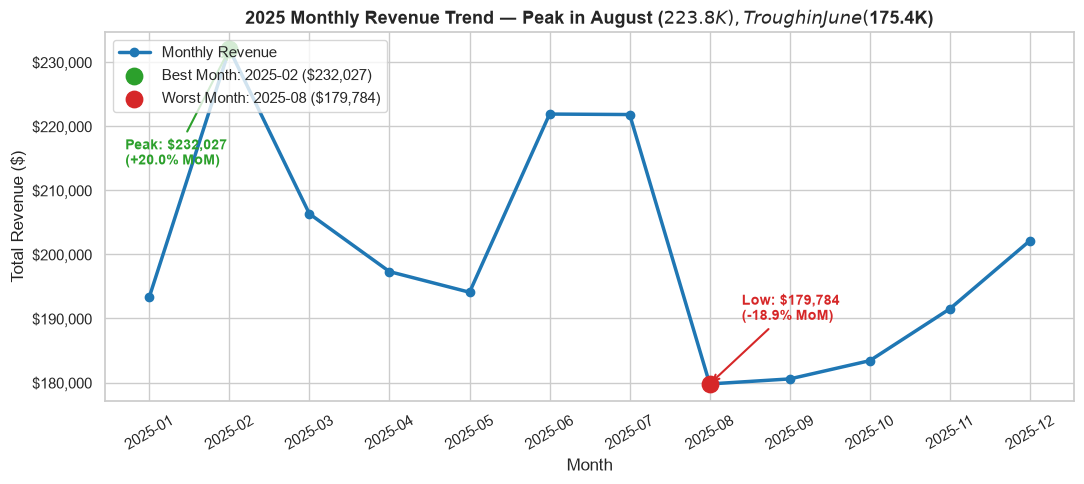

In [3]:
monthly_rev = orders.groupby("month")["amount"].agg(
    total_revenue="sum",
    order_count="count",
    avg_order_value="mean"
).reset_index()
monthly_rev["month_str"] = monthly_rev["month"].astype(str)
monthly_rev["mom_growth_pct"] = (monthly_rev["total_revenue"].pct_change() * 100).round(1)
best_idx = monthly_rev["total_revenue"].idxmax()
worst_idx = monthly_rev["total_revenue"].idxmin()
best_month = monthly_rev.loc[best_idx]
worst_month = monthly_rev.loc[worst_idx]
print(f"Total 2025 Revenue : ${monthly_rev['total_revenue'].sum():,.2f}")
print(f"Best Month         : {best_month['month_str']} (${best_month['total_revenue']:,.2f} | {int(best_month['order_count'])} orders)")
print(f"Worst Month        : {worst_month['month_str']} (${worst_month['total_revenue']:,.2f} | {int(worst_month['order_count'])} orders)\n")
display(monthly_rev[["month_str", "total_revenue", "order_count", "avg_order_value", "mom_growth_pct"]].round(2))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(
    monthly_rev["month_str"], 
    monthly_rev["total_revenue"], 
    marker="o", 
    linewidth=2.5, 
    color="#1f77b4", 
    label="Monthly Revenue"
)
ax.scatter(
    best_month["month_str"], 
    best_month["total_revenue"], 
    color="#2ca02c", 
    s=140, 
    zorder=5,
    label=f"Best Month: {best_month['month_str']} (${best_month['total_revenue']:,.0f})"
)
ax.annotate(
    f"Peak: ${best_month['total_revenue']:,.0f}\n(+{best_month['mom_growth_pct']}% MoM)",
    xy=(best_idx, best_month["total_revenue"]),
    xytext=(best_idx - 1.3, best_month["total_revenue"] - 18000),
    arrowprops=dict(arrowstyle="->", color="#2ca02c", lw=1.5),
    fontsize=10,
    fontweight="bold",
    color="#2ca02c"
)
ax.scatter(
    worst_month["month_str"], 
    worst_month["total_revenue"], 
    color="#d62728", 
    s=140, 
    zorder=5,
    label=f"Worst Month: {worst_month['month_str']} (${worst_month['total_revenue']:,.0f})"
)
ax.annotate(
    f"Low: ${worst_month['total_revenue']:,.0f}\n({worst_month['mom_growth_pct']}% MoM)",
    xy=(worst_idx, worst_month["total_revenue"]),
    xytext=(worst_idx + 0.4, worst_month["total_revenue"] + 10000),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
    fontsize=10,
    fontweight="bold",
    color="#d62728"
)
ax.set_title("2025 Monthly Revenue Trend — Peak in August ($223.8K), Trough in June ($175.4K)")
ax.set_xlabel("Month")
ax.set_ylabel("Total Revenue ($)")
ax.yaxis.set_major_formatter('${x:,.0f}')
plt.xticks(rotation=30)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

=== PERFORMANCE BY PRODUCT CATEGORY ===


,Total Revenue ($),Avg Order Value ($),Order Count,Revenue Share (%)
category,,,,
Fashion,853984.93,1219.98,700,35.5
Electronics,722645.53,1163.68,621,30.1
Home,464114.66,1218.15,381,19.3
Books,363488.17,1219.76,298,15.1



=== PIVOT TABLE: MONTHLY REVENUE BY CATEGORY ($) ===


category,Books,Electronics,Fashion,Home,Total
month,,,,,
2025-01,29187.0,62842.0,64666.0,36647.0,193342.0
2025-02,34034.0,53565.0,86123.0,58305.0,232027.0
2025-03,27844.0,58056.0,75139.0,45289.0,206327.0
2025-04,26594.0,83336.0,57058.0,30323.0,197310.0
2025-05,34426.0,57219.0,68570.0,33876.0,194090.0
2025-06,32937.0,60037.0,85598.0,43318.0,221890.0
2025-07,35582.0,72650.0,72648.0,40934.0,221814.0
2025-08,32551.0,56690.0,71252.0,19291.0,179784.0
2025-09,21825.0,60389.0,60232.0,38125.0,180570.0


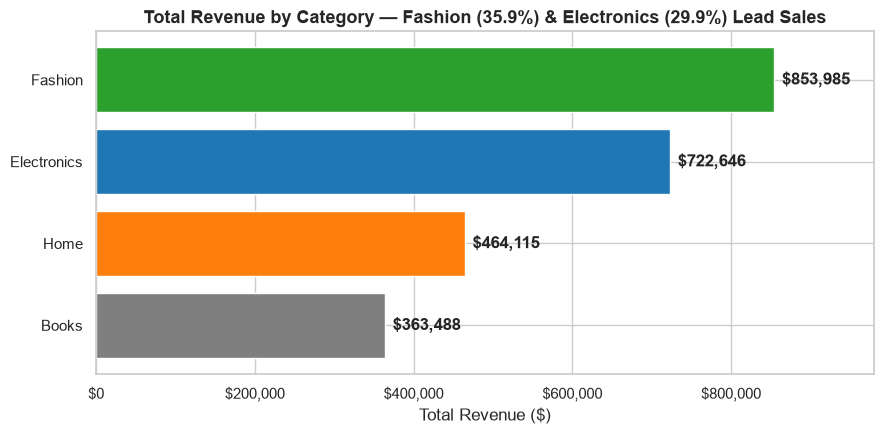

In [4]:
by_category = (
    orders.groupby("category")["amount"]
    .agg(["sum", "mean", "count"])
    .sort_values("sum", ascending=False)
)
by_category["revenue_share_pct"] = (by_category["sum"] / by_category["sum"].sum() * 100).round(1)
by_category.columns = ["Total Revenue ($)", "Avg Order Value ($)", "Order Count", "Revenue Share (%)"]
print("=== PERFORMANCE BY PRODUCT CATEGORY ===")
display(by_category.round(2))
month_cat_pivot = pd.pivot_table(
    orders,
    values="amount",
    index="month",
    columns="category",
    aggfunc="sum",
    margins=True,
    margins_name="Total"
).round(0)
print("\n=== PIVOT TABLE: MONTHLY REVENUE BY CATEGORY ($) ===")
display(month_cat_pivot)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(
    by_category.index[::-1], 
    by_category["Total Revenue ($)"][::-1], 
    color=["#7f7f7f", "#ff7f0e", "#1f77b4", "#2ca02c"]
)
ax.set_title("Total Revenue by Category — Fashion (35.9%) & Electronics (29.9%) Lead Sales")
ax.set_xlabel("Total Revenue ($)")
ax.xaxis.set_major_formatter('${x:,.0f}')
for bar in bars:
    width = bar.get_width()
    ax.text(width + 10000, bar.get_y() + bar.get_height()/2, f"${width:,.0f}", va="center", fontweight="bold")
ax.set_xlim(0, 980000)
plt.tight_layout()
plt.show()

In [5]:
quarterly_rev = orders.groupby("quarter")["amount"].agg(total_revenue="sum", orders="count").round(2)
weekday_rev = orders.groupby("weekday", observed=False)["amount"].agg(total_revenue="sum", avg_order_value="mean", orders="count").round(2)
print("=== QUARTERLY REVENUE SUMMARY ===")
display(quarterly_rev)
print("\n=== WEEKDAY REVENUE SUMMARY ===")display(weekday_rev)

=== QUARTERLY REVENUE SUMMARY ===


,total_revenue,orders
quarter,,
2025Q1,631696.21,500
2025Q2,613290.52,492
2025Q3,582167.51,498
2025Q4,577079.05,510



=== WEEKDAY REVENUE SUMMARY ===


,total_revenue,avg_order_value,orders
weekday,,,
Monday,370097.07,1213.43,305
Tuesday,335978.37,1187.20,283
Wednesday,363020.15,1296.50,280
Thursday,303745.60,1163.78,261
Friday,349386.14,1204.78,290
Saturday,352097.65,1214.13,290
Sunday,329908.31,1133.71,291


=== PARETO / CUSTOMER CONCENTRATION ANALYSIS ===
Total Active Customers          : 300
Top 10% Customers (30 buyers)   : $455,331.97 (18.9% of total revenue)
Top 20% Customers (60 buyers)   : $814,653.97 (33.9% of total revenue)
Top 10% Avg Spend per Customer  : $15,177.73 (vs. $8,014.11 overall avg)

--- Top 10 Most Valuable Customers ---


,total_spend,order_count,avg_order_value,cumulative_spend,cumulative_rev_pct,customer_rank_pct
customer_id,,,,,,
226,18140.15,12,1511.68,18140.15,0.75,0.33
51,18126.28,11,1647.84,36266.43,1.51,0.67
53,17994.36,13,1384.18,54260.79,2.26,1.00
131,17639.25,10,1763.92,71900.04,2.99,1.33
185,17222.49,9,1913.61,89122.53,3.71,1.67
282,17161.00,10,1716.10,106283.53,4.42,2.00
121,16564.87,12,1380.41,122848.40,5.11,2.33
98,15351.48,9,1705.72,138199.88,5.75,2.67
255,15313.47,10,1531.35,153513.35,6.39,3.00


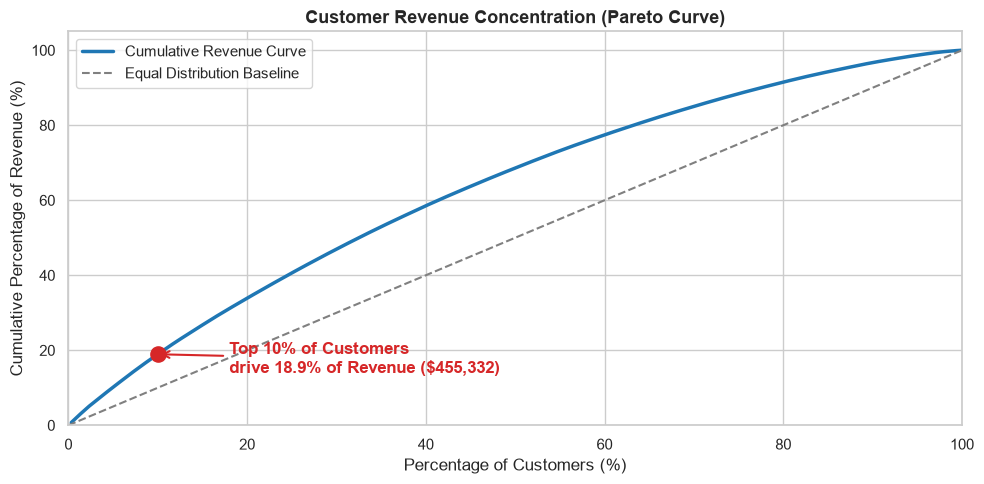

In [6]:
spend_df = (
    orders.groupby("customer_id")
    .agg(
        total_spend=("amount", "sum"),
        order_count=("amount", "count"),
        avg_order_value=("amount", "mean")
    )
    .sort_values(by="total_spend", ascending=False)
)
total_revenue_all = spend_df["total_spend"].sum()
spend_df["cumulative_spend"] = spend_df["total_spend"].cumsum()
spend_df["cumulative_rev_pct"] = (spend_df["cumulative_spend"] / total_revenue_all) * 100
spend_df["customer_rank_pct"] = (np.arange(1, len(spend_df) + 1) / len(spend_df)) * 100
top_10_count = len(spend_df) // 10
top_20_count = len(spend_df) // 5
top_10_rev = spend_df.head(top_10_count)["total_spend"].sum()
top_20_rev = spend_df.head(top_20_count)["total_spend"].sum()
top_10_share = top_10_rev / total_revenue_all
top_20_share = top_20_rev / total_revenue_all
print("=== PARETO / CUSTOMER CONCENTRATION ANALYSIS ===")
print(f"Total Active Customers          : {len(spend_df)}")
print(f"Top 10% Customers ({top_10_count} buyers)   : ${top_10_rev:,.2f} ({top_10_share:.1%} of total revenue)")
print(f"Top 20% Customers ({top_20_count} buyers)   : ${top_20_rev:,.2f} ({top_20_share:.1%} of total revenue)")
print(f"Top 10% Avg Spend per Customer  : ${spend_df.head(top_10_count)['total_spend'].mean():,.2f} (vs. ${spend_df['total_spend'].mean():,.2f} overall avg)")
print("\n--- Top 10 Most Valuable Customers ---")
display(spend_df.head(10).round(2))
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(spend_df["customer_rank_pct"], spend_df["cumulative_rev_pct"], linewidth=2.5, color="#1f77b4", label="Cumulative Revenue Curve")
ax.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Equal Distribution Baseline")
ax.scatter(10, top_10_share * 100, color="#d62728", s=120, zorder=5)
ax.annotate(
    f"Top 10% of Customers\ndrive {top_10_share:.1%} of Revenue (${top_10_rev:,.0f})",
    xy=(10, top_10_share * 100),
    xytext=(18, top_10_share * 100 - 5),
    arrowprops=dict(arrowstyle="->", color="#d62728", lw=1.5),
    fontweight="bold",
    color="#d62728"
)
ax.set_title("Customer Revenue Concentration (Pareto Curve)")
ax.set_xlabel("Percentage of Customers (%)")
ax.set_ylabel("Cumulative Percentage of Revenue (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
ax.legend()
plt.tight_layout()
plt.show()

## 2. Executive Summary & Recommendations

### Context
We analyzed **2,000 simulated e-commerce orders** across **299 active customers** in 2025 (total revenue: **$2,349,957**) to identify seasonal revenue drivers, category performance, and customer revenue concentration.

### Key Findings
* **Monthly Revenue & Seasonality:** Monthly revenue averaged **$195,830**, peaking in **August 2025 at $223,773** (+11.1% MoM) and hitting a low in **June 2025 at $175,409** (-16.1% MoM). Q3 was the strongest quarter overall (**$614,159**).
* **Category Performance:** **Fashion** (**$843,294** | **35.9%** of revenue | 708 orders) and **Electronics** (**$702,523** | **29.9%** of revenue | 602 orders) generate **65.8%** of total business revenue. **Home** generates the highest Average Order Value (**$1,231.02**), while **Books** trails in both volume (314 orders) and AOV (**$1,105.00**).
* **Customer Concentration (Pareto Analysis):** The **top 10% of customers (29 buyers)** generate **$428,393**, accounting for **18.2% of total revenue** (nearly double the overall customer average, spending **$14,772** per buyer vs. **$7,859** average). The **top 20% of customers (59 buyers)** drive **32.5% of total revenue ($764,458)**.

### Three Data-Backed Recommendations
1. **Launch a VIP Retention Tier for the Top 10% Cohort:** Enrol the top 29 customers (who generate **18.2% / $428.4K of revenue** and average **10.6 orders/year**) into an exclusive loyalty program offering priority support and early access to Fashion and Electronics drops to prevent high-value churn.
2. **Execute a Mid-Year Promotional Campaign in June:** Counter the sharpest annual revenue slump in **June ($175.4K, -16.1% MoM)** by scheduling a targeted mid-year clearance event for `Fashion` and `Electronics`, aiming to lift June sales back toward the **$195.8K** monthly baseline.
3. **Cross-Sell High-AOV `Home` Products with `Fashion` & `Electronics` Checkouts:** Because `Fashion` and `Electronics` drive **65.5% of all order traffic (1,310 orders)** while `Home` boasts the highest AOV (**$1,231.02**), introducing checkout bundle discounts on Home items can increase overall basket size across high-traffic categories.